# Visualization tutorial

This notebook covers some of the core visualization functionality in `quantEM` 

**Outline**

1. **Dataset `.show`** — thin wrapper around `show_2d` for `Dataset` objects  
2. **`show_2d`** — main 2D visualization API  
3. **`linescan`** — 1D profiles through 2D images or 3D stacks  

Arthur McCray  
April 15, 2026


In [1]:
%load_ext autoreload
%autoreload 2

import matplotlib.pyplot as plt
import numpy as np
import quantem as em
import torch
from quantem.core.datastructures import Dataset4dstem
from quantem.core.visualization import ShowParams, linescan, show_2d

print(em.__version__)

0.1.10


In [2]:
# --- Load example data ---
cameraman = np.load("../../data/cameraman.npy")
cameraman_torch = torch.from_numpy(cameraman)

ducky_ds: Dataset4dstem = em.io.load("../../data/ducky_251105_20mrad_500A-df_4A-step_5e+04-dose_clean.zip")
dp = ducky_ds.dp_mean  # mean diffraction pattern
dp_np = dp.array  # ndarray for numpy-only APIs (e.g. linescan)
real_sampling = ducky_ds.sampling[0]  # real-space Å/px
recip_sampling = ducky_ds.sampling[2]  # reciprocal-space 1/Å per px

print(f"cameraman  : {cameraman.shape}")
print(f"ducky 4D   : {ducky_ds.shape}, sampling={ducky_ds.sampling}")
print(f"mean DP    : {dp.shape}, dp_np {dp_np.shape}")


cameraman  : (512, 512)
ducky 4D   : (37, 37, 200, 200), sampling=[4.    4.    0.025 0.025]
mean DP    : (200, 200), dp_np (200, 200)


## 1. Dataset show

Most `Dataset` types expose a `.show(...)` helper that delegates to `show_2d`.


quantem Dataset named 'ducky_251105_clean_dp_mean'
  shape: (200, 200)
  dtype: float32
  device: cpu
  origin: [0. 0.]
  sampling: [0.025 0.025]
  units: ['A^-1', 'A^-1']
  signal units: 'arb. units'


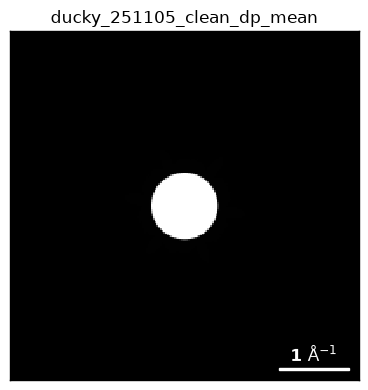

In [3]:
ducky_ds.get_dp_mean() # compute the mean diffraction pattern
print(ducky_ds.dp_mean) # the mean diffraction pattern is a Dataset2d
ducky_ds.dp_mean.show();

For `Dataset4d`, `show` takes an optional scan index `(scan_y, scan_x)`; if omitted, the panel at `(0, 0)` is used.

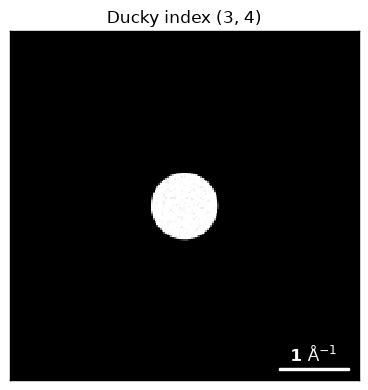

In [4]:
ind = (3,4)
ducky_ds.show(ind, title=f"Ducky index {ind}");

## 2. `show_2d`

### Layouts and quick start

Pass a 2D array, a row (list of arrays), or a grid (nested list). Supported element types include 2D `np.ndarray`, 2D `torch.Tensor`, and `Dataset2d`.

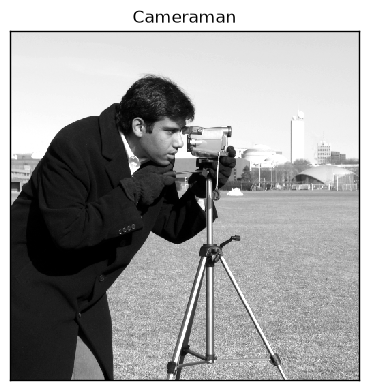

In [5]:
# Single image
show_2d(cameraman, title="Cameraman");

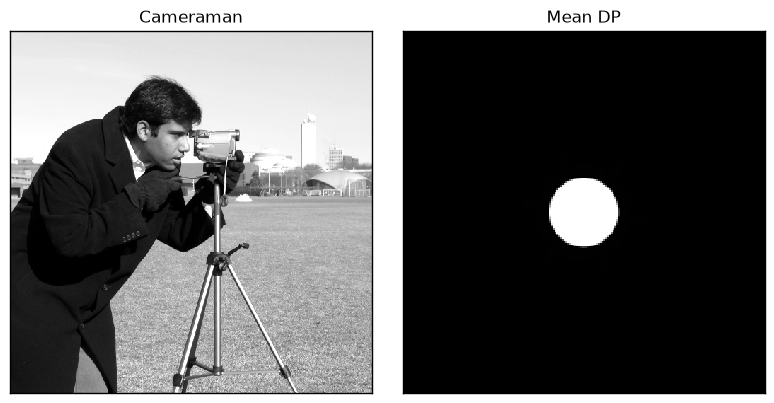

In [6]:
# Row of images
show_2d([cameraman_torch, dp], title=["Cameraman", "Mean DP"]);

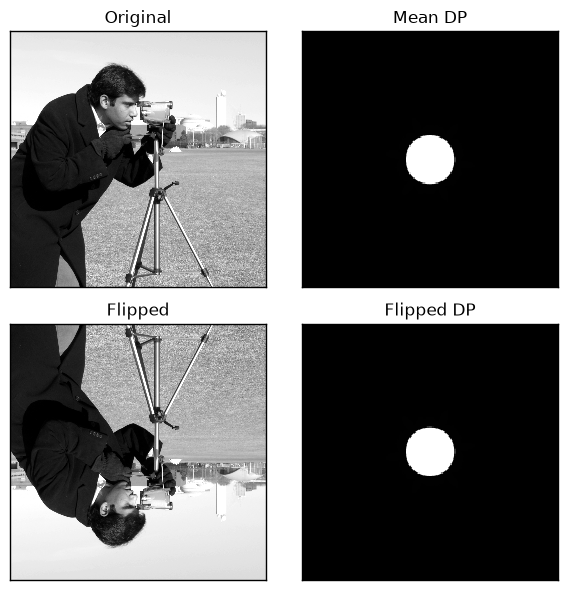

In [7]:
# 2×2 grid and specifying axsize
show_2d(
    [[cameraman, dp], [cameraman[::-1], dp[::-1]]],
    axsize=(3,3),
    title=[["Original", "Mean DP"], ["Flipped", "Flipped DP"]],
);

### Return values

`show_2d` returns `(fig, axs)` for further matplotlib edits. Current implementation follows `matplotlib` defaults, where the `ax` will be a `Axes` object if the plot is 1 row and 1 column, otherwise a `list[Axes]` or `list[list[Axes]]`


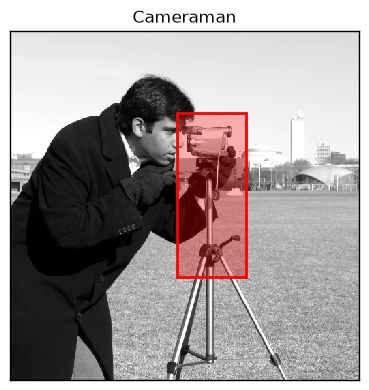

In [8]:
from matplotlib.patches import Rectangle

fig, axs = show_2d(cameraman, title="Cameraman")  
# add an overlay square
axs.add_patch(Rectangle((245, 120), 100, 240, fc=(1, 0, 0, 0.3), ec=(1, 0, 0, 1), lw=2)) 
plt.show()

### Reusing an existing figure

Pass `figax=(fig, ax)` to draw into axes you created yourself

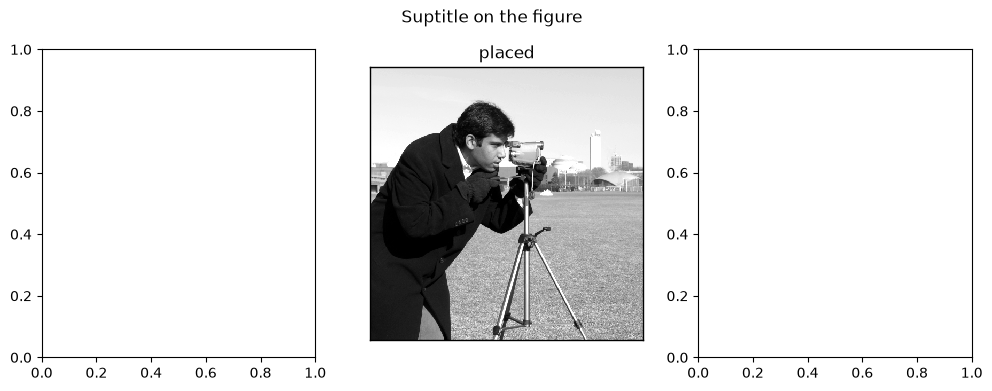

In [9]:
fig, axs = plt.subplots(nrows=1, ncols=3, figsize=(12, 4))
show_2d(cameraman, figax=(fig, axs[1]), title="placed")
plt.suptitle("Suptitle on the figure")
plt.show()

### Colorbars

Set `cbar=True` to add a colorbar (one per panel when using a grid).


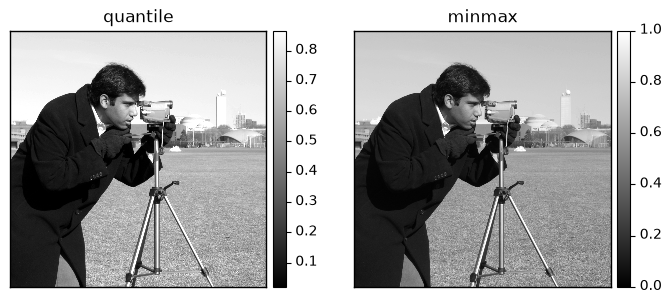

In [10]:
# Real data with colorbar
show_2d(
    [cameraman, cameraman], cbar=True, norm=["quantile", "minmax"], title=["quantile", "minmax"]
);

### Extra kwargs
There are some other `kwargs`, but for fine-tuned control we recommend directly adjusting the `matplotlib` figure using one of the above methods. `force_show` is useful for when plotting multiple images sequentially or for monitoring a process.

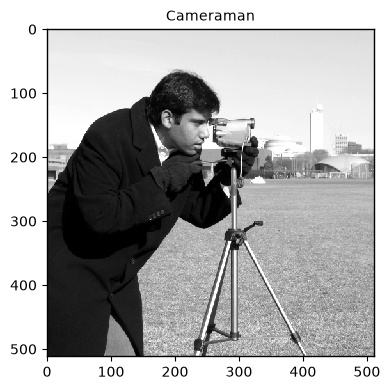

In [11]:
show_2d(cameraman, title="Cameraman", title_fontsize=10, show_ticks=True, force_show=True);

### Docstring in the notebook

Use `?show_2d` or `help(show_2d)` for the API


In [12]:
?show_2d 

Signature:
show_2d(
    arrays: Union[NDArray, torch.Tensor, ForwardRef('Dataset2d'), collections.abc.Sequence[Union[NDArray, torch.Tensor, ForwardRef('Dataset2d')]], collections.abc.Sequence[collections.abc.Sequence[Union[NDArray, torch.Tensor, ForwardRef('Dataset2d')]]]],
    *,
    norm: quantem.core.visualization.custom_normalizations.NormalizationConfig | quantem.core.visualization.show_params.ShowParams.Norm | dict | str | None | collections.abc.Sequence[quantem.core.visualization.custom_normalizations.NormalizationConfig | quantem.core.visualization.show_params.ShowParams.Norm | dict | str] | collections.abc.Sequence[collections.abc.Sequence[quantem.core.visualization.custom_normalizations.NormalizationConfig | quantem.core.visualization.show_params.ShowParams.Norm | dict | str]] = None,
    scalebar: quantem.core.visualization.visualization_utils.ScalebarConfig | quantem.core.visualization.show_params.ShowParams.Scalebar | dict | bool | None | collections.abc.Sequence[quantem.c

### Normalization (`ShowParams.Norm`)

`ShowParams.Norm` is a tab-completable dataclass that controls how pixel values are mapped to the display range. It has two main levers:

| | Options | Role |
|--|---------|------|
| **Interval** (`interval_type`) | `"quantile"`, `"manual"`, `"centered"` | Set the plotting limits |
| **Stretch** (`stretch_type`) | `"linear"`, `"power"`, `"logarithmic"`, `"asinh"` | How values map within those limits |

Class methods such as `ShowParams.Norm.log_auto()` bundle common interval + stretch choices.


In [13]:
?ShowParams.Norm

Init signature:
ShowParams.Norm(
    interval_type: Optional[Literal['quantile', 'manual', 'centered']] = None,
    stretch_type: Literal['linear', 'power', 'logarithmic', 'asinh'] = 'linear',
    lower_quantile: float = 0.02,
    upper_quantile: float = 0.98,
    vmin: float | None = None,
    vmax: float | None = None,
    vcenter: float = 0.0,
    half_range: float | None = None,
    power: float = 1.0,
    logarithmic_index: float = 1000.0,
    asinh_linear_range: float = 0.1,
) -> None
Docstring:     
Normalization parameters for ``show_2d``.

Controls how pixel values are mapped to the [0, 1] display range via
an *interval* (which values to keep) and a *stretch* (non-linear
transfer function).

If ``vmin`` or ``vmax`` is set and ``interval_type`` is left as the
default ``"quantile"``, it is automatically changed to ``"manual"``.
Likewise, setting ``vcenter`` to a non-zero value or providing
``half_range`` auto-selects ``"centered"``.

Parameters
----------
interval_type : ``"quan

#### Interval types


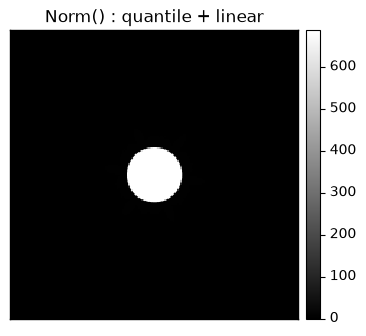

In [14]:
# Default: quantile + linear (clips range to be [2%, 98%], and with a linear 1:1 mapping)
show_2d(dp, norm=ShowParams.Norm(), title="Norm() : quantile + linear", cbar=True);

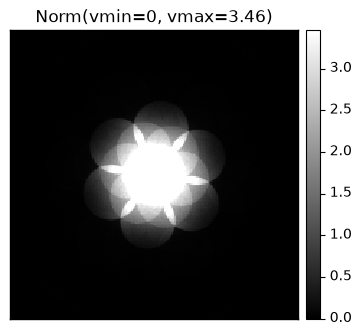

In [15]:
# Manual interval — set vmin/vmax (interval_type is auto-inferred to "manual")
vmax = dp.max()*0.005
show_2d(
    dp,
    norm=ShowParams.Norm(vmin=0, vmax=vmax),
    title=f"Norm(vmin=0, vmax={vmax:.2f})",
    cbar=True,
);

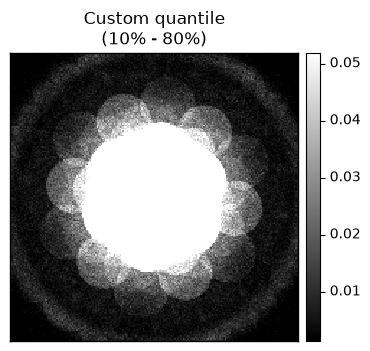

In [16]:
# Specifying quantile limits (interval_type is auto-inferred to "quantile")
show_2d(
    dp,
    norm=ShowParams.Norm(lower_quantile=0.1, upper_quantile=0.8),
    title="Custom quantile\n(10% - 80%)",
    cbar=True,
);


<string>:14: UserWarning: lower_quantile/upper_quantile are ignored when interval_type='manual'.


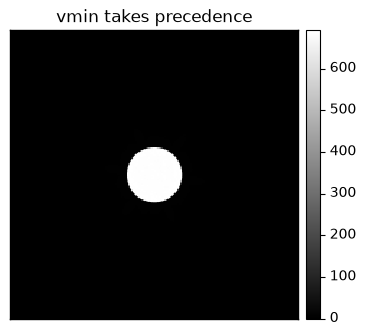

In [17]:
# Trying to combine different interval or stretch types will raise warnings and will default to one
show_2d(
    dp,
    norm=ShowParams.Norm(vmin=0, upper_quantile=0.5),
    title="vmin takes precedence",
    cbar=True,
);


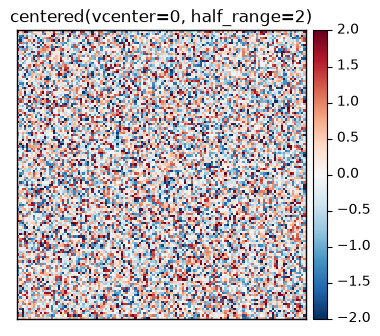

In [18]:
# Centered interval — symmetric around vcenter
centered_data = np.random.RandomState(0).randn(128, 128)
show_2d(
    centered_data,
    norm=ShowParams.Norm.centered(vcenter=0, half_range=2),
    title="centered(vcenter=0, half_range=2)",
    cmap="RdBu_r",
    cbar=True,
);

#### Stretch types


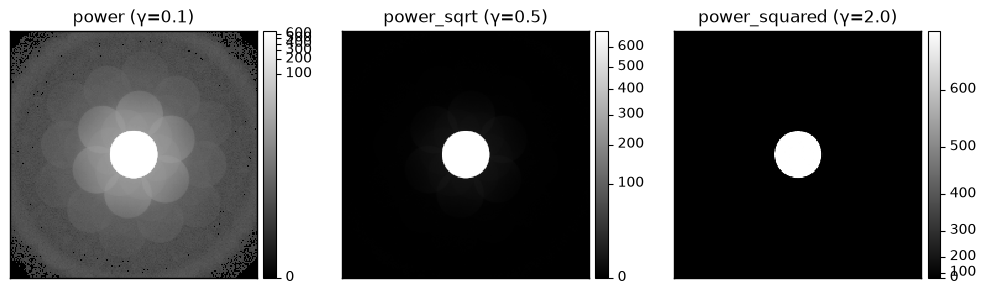

In [19]:
# Power stretch for different exponents 
show_2d(
    [dp, dp, dp],
    norm=[
        ShowParams.Norm(power=0.1),
        ShowParams.Norm.power_sqrt(), # alias for power=0.5
        ShowParams.Norm.power_squared(), # alias for power=2.0
    ],
    title=["power (γ=0.1)", "power_sqrt (γ=0.5)", "power_squared (γ=2.0)"],
    cbar=True,
);

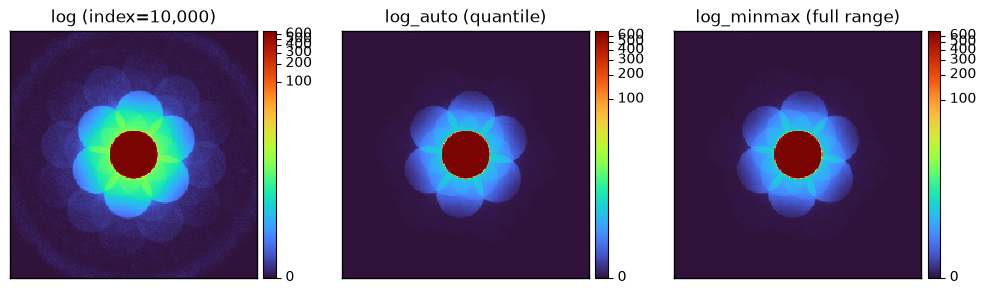

In [20]:
# Log stretch — good for diffraction data with high dynamic range
show_2d(
    [dp, dp, dp],
    norm=[
        ShowParams.Norm(stretch_type="logarithmic", logarithmic_index=1e4),
        ShowParams.Norm.log_auto(), # quantile stretch, default index = 1e3
        ShowParams.Norm.log_minmax(), # full range stretch, default index = 1e3
    ],
    title=["log (index=10,000)", "log_auto (quantile)", "log_minmax (full range)"],
    cmap="turbo",
    cbar=True,
);

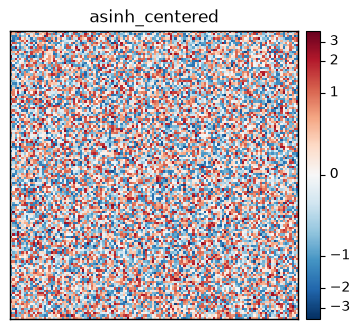

In [21]:
# Asinh stretch — soft compression, centred
show_2d(
    centered_data,
    norm=ShowParams.Norm.asinh_centered(vcenter=0),
    title="asinh_centered",
    cmap="RdBu_r",
    cbar=True,
);

#### String presets (no `ShowParams` import)

Pass a string to `norm=` for presets, for example `"linear_auto"` / `"quantile"`, `"minmax"`, `"linear_centered"`, `"log_auto"`, `"log_minmax"`, `"power_sqrt"`, `"power_squared"`, `"asinh_centered"`. These line up with the `ShowParams.Norm.*` class methods of the same names.


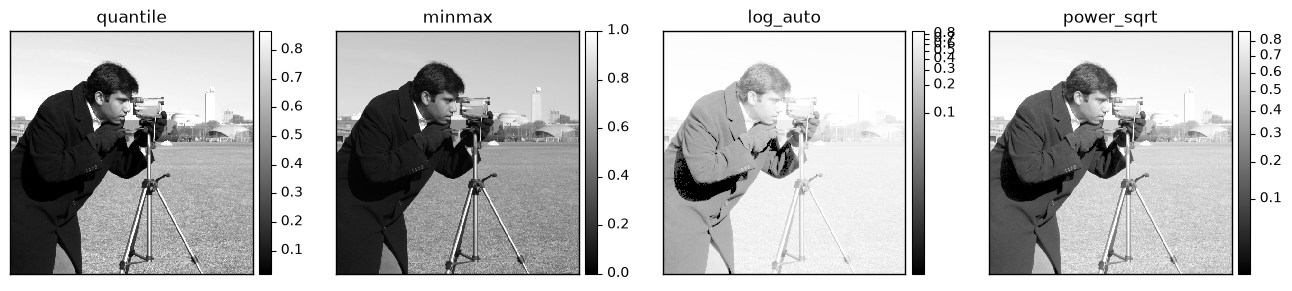

In [22]:
show_2d(
    [cameraman, cameraman, cameraman, cameraman],
    norm=["quantile", "minmax", "log_auto", ShowParams.Norm.power_sqrt()],
    title=["quantile", "minmax", "log_auto", "power_sqrt"],
    cbar=True,
);

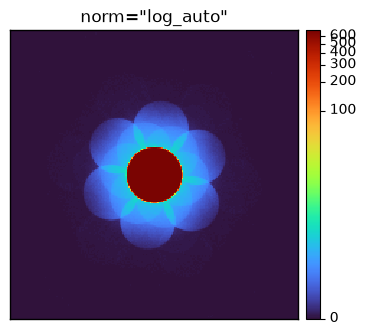

In [23]:
# Single string preset
show_2d(dp, norm="log_auto", cmap="turbo", cbar=True, title='norm="log_auto"');

You can also pass `lower_quantile`, `upper_quantile`, `vmin`, `vmax`, and related kwargs directly to `show_2d`

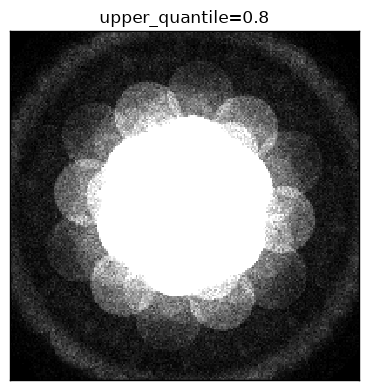

In [24]:
show_2d(dp, upper_quantile=0.8, title='upper_quantile=0.8');

### Scale bar (`ShowParams.Scalebar`)

`ShowParams.Scalebar` draws a labelled bar. Set `sampling` (physical extent per pixel in image coordinates) and `units`; optional arguments adjust length, position, color, and typography.


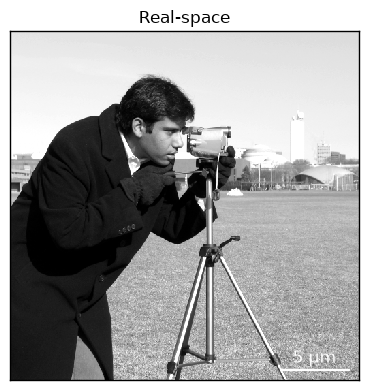

In [25]:
# Real-space scale bar, units will be converted to a sensible value
show_2d(
    cameraman,
    scalebar=ShowParams.Scalebar(sampling=500, units="A"),
    title="Real-space",
);

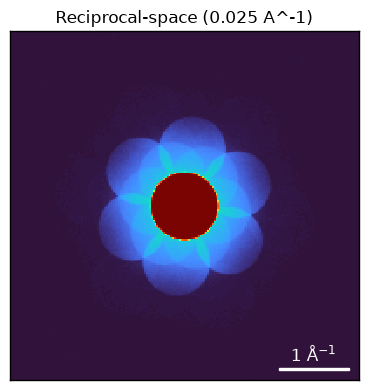

In [26]:
# Reciprocal-space scale bar using actual ducky sampling
show_2d(
    dp,
    norm=ShowParams.Norm.log_auto(),
    scalebar=ShowParams.Scalebar(sampling=ducky_ds.sampling[2], units=ducky_ds.units[2]),
    cmap="turbo",
    title=f"Reciprocal-space ({ducky_ds.sampling[2]:.3f} {ducky_ds.units[2]})",
);

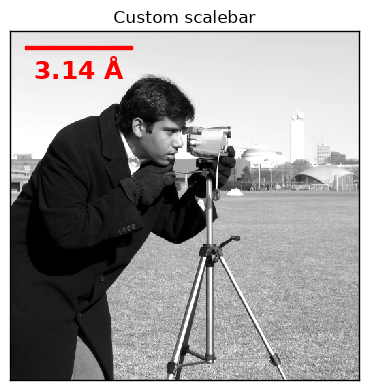

In [27]:
# Customized scalebar 
show_2d(
    cameraman,
    scalebar=ShowParams.Scalebar(
        sampling=0.02,
        units="A",
        length=3.14, # length in physical units
        color="red",
        loc="upper left",
        width_px=4, # thickness of the bar
        fontsize=18,
        bold=True,
    ),
    title="Custom scalebar",
);

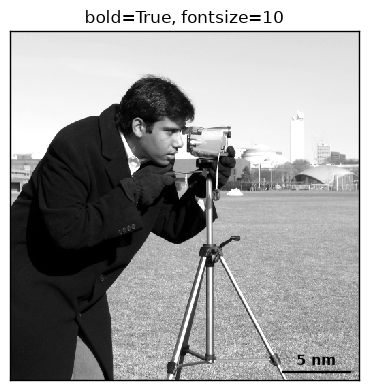

In [28]:
# Bold, smaller font
show_2d(
    cameraman,
    scalebar=ShowParams.Scalebar(sampling=0.5, units="Å", bold=True, fontsize=10, color="black"),
    title="bold=True, fontsize=10",
);


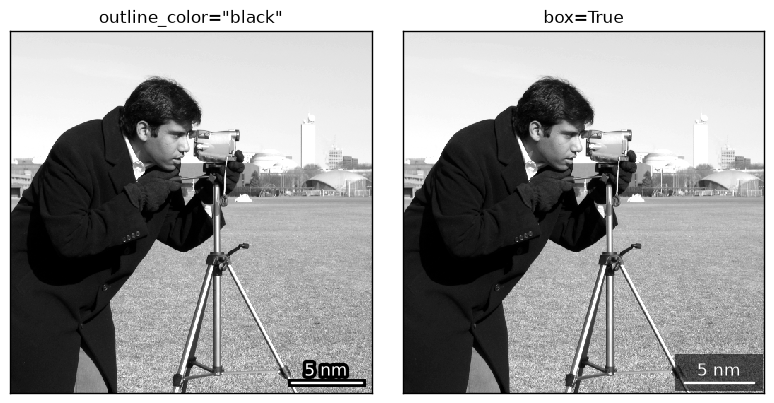

In [29]:
# Outline or a box behind the bar keeps it readable on any background
show_2d(
    [cameraman, cameraman],
    scalebar=[
        ShowParams.Scalebar(sampling=0.5, units="Å", outline_color="black", outline_width=5),
        ShowParams.Scalebar(sampling=0.5, units="Å", box=True, box_color="black", box_alpha=0.6),
    ],
    title=['outline_color="black"', "box=True"],
);

### Colormaps

Pass any matplotlib colormap name or object as `cmap`. The library also registers `"turbo_black"` (turbo with a black floor at low values).


<class 'matplotlib.colors.ListedColormap'>


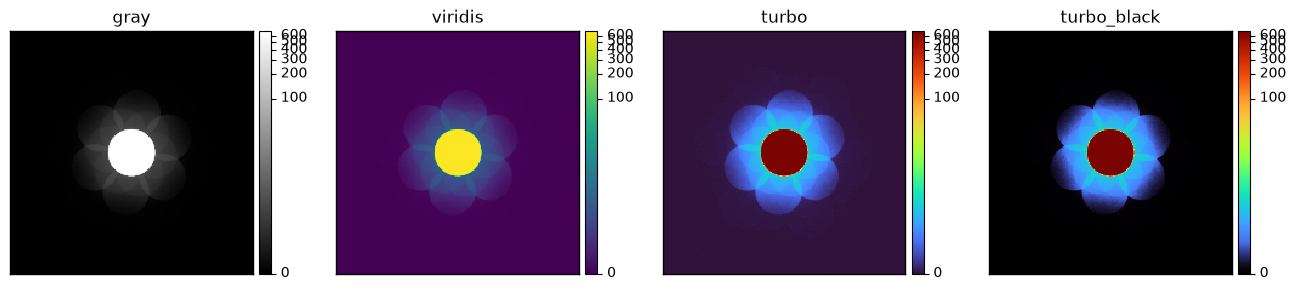

In [30]:
Viridis = plt.get_cmap('viridis')
print(type(Viridis))
show_2d(
    [dp, dp, dp, dp],
    cmap=["gray", Viridis, "turbo", "turbo_black"],
    title=["gray", "viridis", "turbo", "turbo_black"],
    norm=ShowParams.Norm.log_auto(),
    cbar=True,
);

If you [want more colormaps](https://arxiv.org/abs/1509.03700) you can create your own, or I suggest using those from [colorcet](https://colorcet.com/index.html). These can be passed to `show_2d` as well.

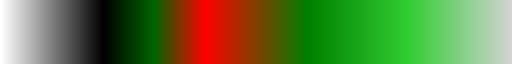

In [31]:
from matplotlib.colors import LinearSegmentedColormap

# https://xkcd.com/2537/
node_colors = ["white", "black", "darkgreen", "red", "green", "limegreen", "lightgrey"]
node_positions = [0, 0.2, 0.3, 0.4, 0.6, 0.8, 1]

painbow = LinearSegmentedColormap.from_list("painbow", list(zip(node_positions, node_colors)))

painbow

(<Figure size 400x400 with 1 Axes>, <Axes: title={'center': 'custom cmap'}>)

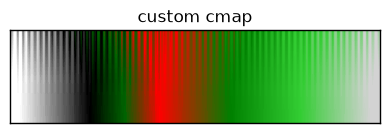

In [32]:
test_im = em.io.read_2d("../../data/colourmaptest.tif", file_type="tiff") # rosettasciio doesn't recognize "tif"... requires "tiff"
show_2d(test_im, title="custom cmap", cmap=painbow)

### Complex-valued data

Complex arrays are shown using amplitude (value) and phase (hue).


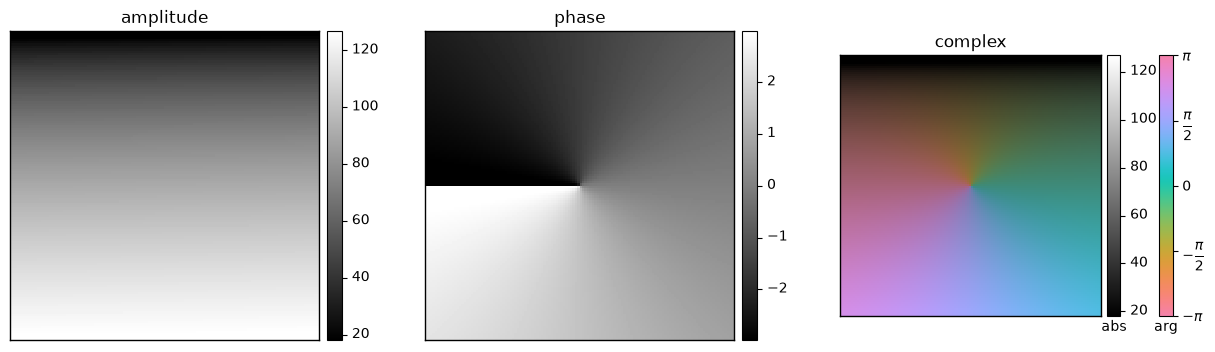

In [33]:
# Complex data — amplitude + phase colorbars
amp = np.arange(128**2).reshape(128, 128)**0.5
x, y = np.meshgrid(np.linspace(-1, 1, 128), np.linspace(-1, 1, 128))
phase = np.arctan2(y, x)
cmplx = amp * np.exp(1j * phase)
show_2d(
    [amp, phase, cmplx],
    title=["amplitude", "phase", "complex"],
    cbar=True,
    axsize=(5,5)
);


### Combined images

With `combine_images=True`, each array is mapped to a distinct hue and combined into one RGB image.


(<Figure size 400x400 with 1 Axes>,
 <Axes: title={'center': 'combined orig + flipped'}>)

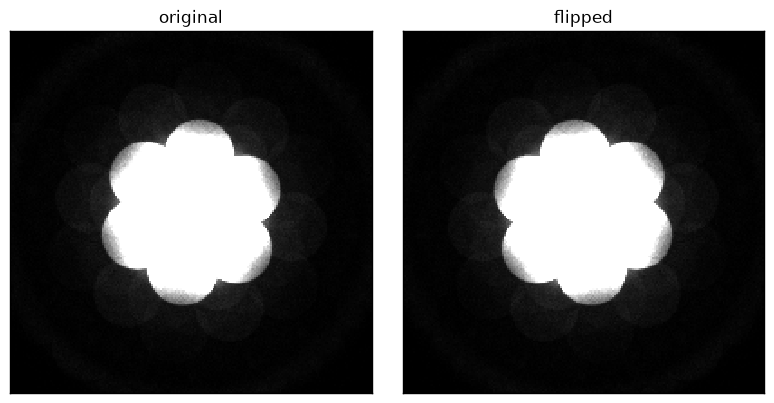

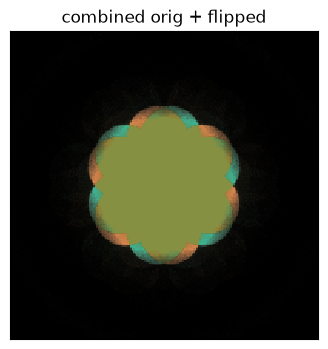

In [34]:
dp1 = dp.array
dp2 = np.fliplr(dp1)
show_2d(
    [dp1, dp2],
    cmap='gray',
    upper_quantile=0.85,
    title=['original', 'flipped'],
)
show_2d(
    [dp1, dp2],
    cmap='turbo',
    upper_quantile=0.85,
    combine_images=True,
    title="combined orig + flipped",
)

### Grid layouts with per-panel settings

`norm`, `scalebar`, `cmap`, `cbar`, and `title` may be a single value (broadcast) or a nested list with the same "rows x columns" structure as the input grid.


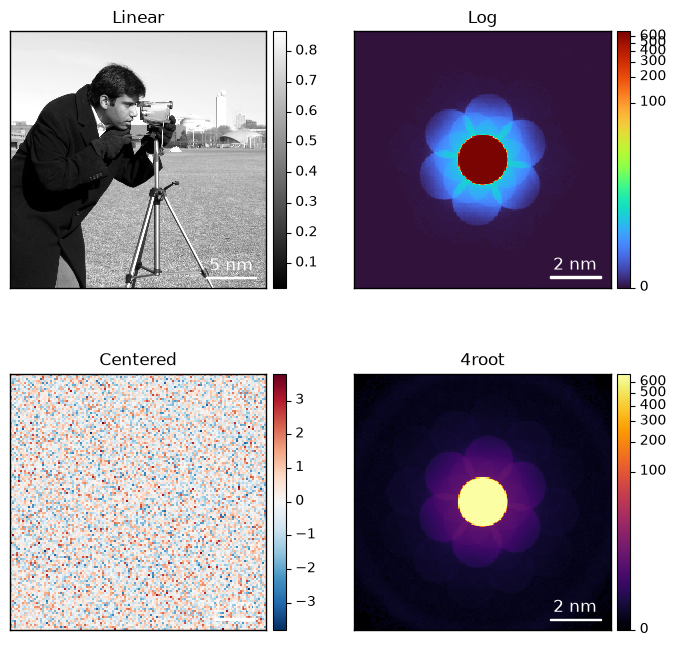

In [35]:
show_2d(
    [[cameraman, dp], [centered_data, dp]],
    norm=[
        [ShowParams.Norm(), ShowParams.Norm.log_auto()],
        [ShowParams.Norm.centered(), ShowParams.Norm(power=0.25)],
    ],
    cmap=[
        ["gray", "turbo"],
        ["RdBu_r", "inferno"],
    ],
    title=[
        ["Linear", "Log"],
        ["Centered", "4root"],
    ],
    cbar=True,
    scalebar=ShowParams.Scalebar(sampling=0.5, units="Å"),
);

### Saving figures

Pass `save=` with a filesystem path (e.g. `.png`, `.pdf`, `.svg`). Extra kwargs such as `dpi` are passed to `Figure.savefig`.


Saving figure to /tmp/tmp192ty714/example.png

File exists: True, size: 307263 bytes


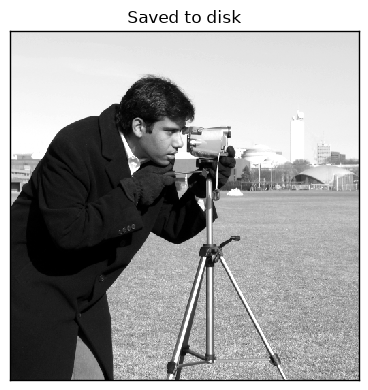

In [36]:
from pathlib import Path
import tempfile

with tempfile.TemporaryDirectory() as tmp:
    tmp = Path(tmp)
    path = tmp / "example.png"
    show_2d(cameraman, save=path, title="Saved to disk")
    print(f"\nFile exists: {path.exists()}, size: {path.stat().st_size} bytes")

### Dict and string forms (backward compatible)

Dict and string forms for `norm` and `scalebar` remain supported.


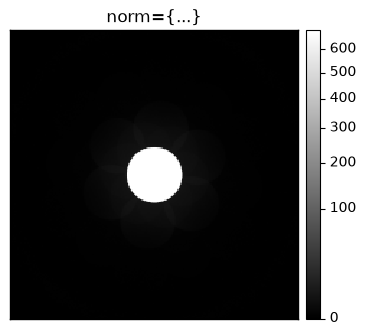

In [37]:
# Dict norm
show_2d(dp, norm={"stretch_type": "power", "power": 0.5}, cbar=True, title="norm={...}");

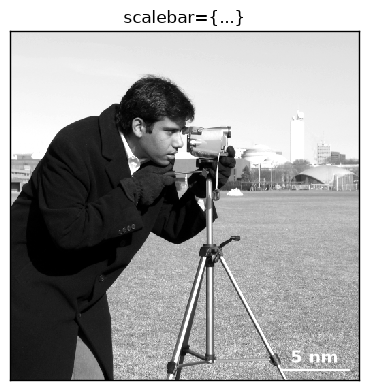

In [38]:
# Dict scalebar
show_2d(cameraman, scalebar={"sampling": 0.5, "units": "Å"}, title="scalebar={...}");

## 3. `linescan`

Extract a **1D intensity profile** along a segment through a **2D** image, or **depth × position** profiles for a **3D** `(Z, Y, X)` stack (the same line in each slice; the overlay uses the mean along depth).

| Argument | Role |
|----------|------|
| `center` | `(row, col)` pivot; default = image center |
| `phi` | Angle in degrees |
| `linewidth` | Width in pixels perpendicular to the line (`skimage.measure.profile_line`) |
| `line_len` | Segment length in pixels; `-1` extends to the image boundary |
| `sampling` | Scale for profile positions (scalar or `(dy, dx)` with equal entries) |
| `sampling_units` | Axis label when `sampling` is set (default `Å`) |
| `show` | If `True`, draw profile + image with line overlay |
| `return_fig` | With `show=True`, return `(positions, profile, (fig, axes))` |
| Other kwargs | Forwarded to `show_2d` on the image panel (`norm`, `cmap`, `title`, line `color`, …) |


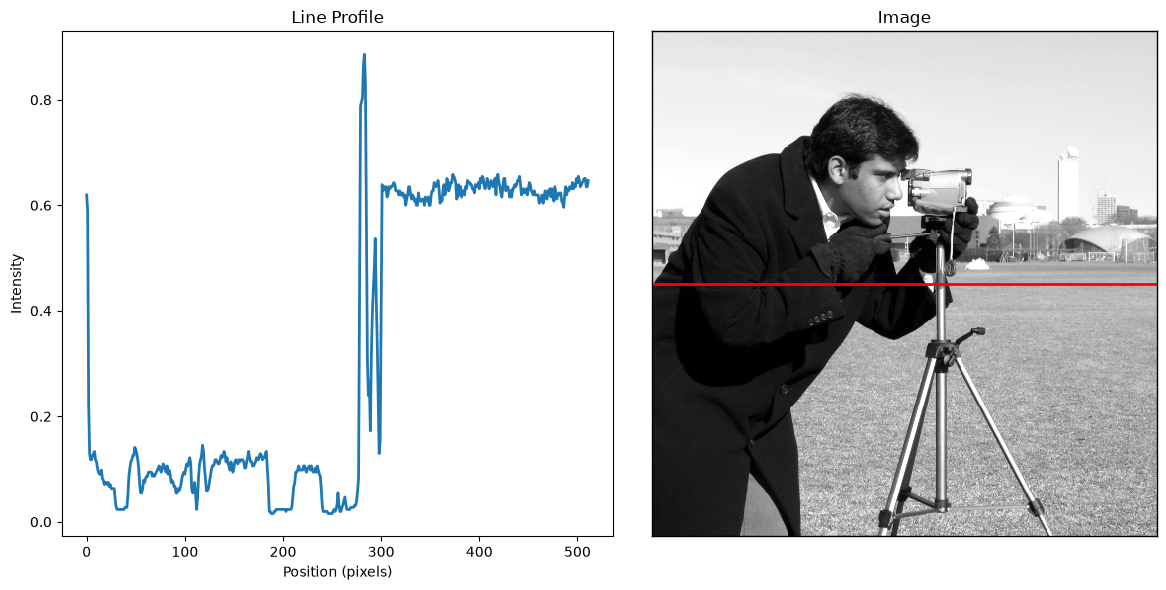

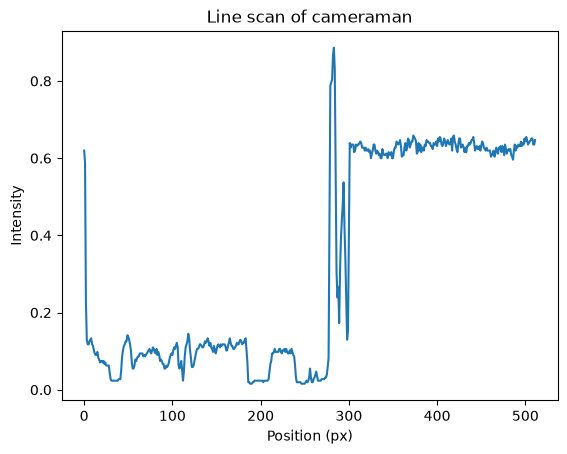

In [39]:
# Silent use: pixel positions unless sampling= is passed
pos, prof = linescan(cameraman, show=True)

fig, ax = plt.subplots()
ax.plot(pos, prof)
ax.set_xlabel("Position (px)")
ax.set_ylabel("Intensity")
ax.set_title("Line scan of cameraman")
plt.show()


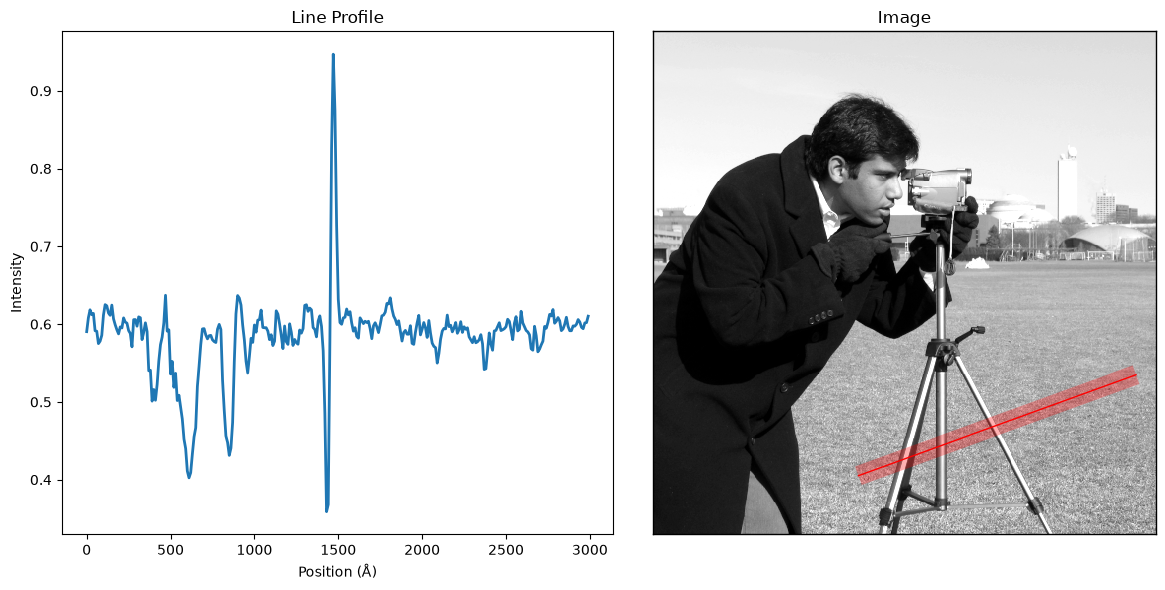

In [40]:
# Geometry and linewidth (kwargs style the image like show_2d)
center = (400, 350)
phi = -20  # angle of the line scan in degrees
linewidth = 20
line_len = 300  # default -1 extends to the image boundary
sampling = (10, 10)  # physical units per pixel in y, x
sampling_units = "Å"
pos, prof = linescan(
    cameraman,
    show=True,
    center=center,
    phi=phi,
    linewidth=linewidth,
    line_len=line_len,
    sampling=sampling,
    sampling_units=sampling_units,
)


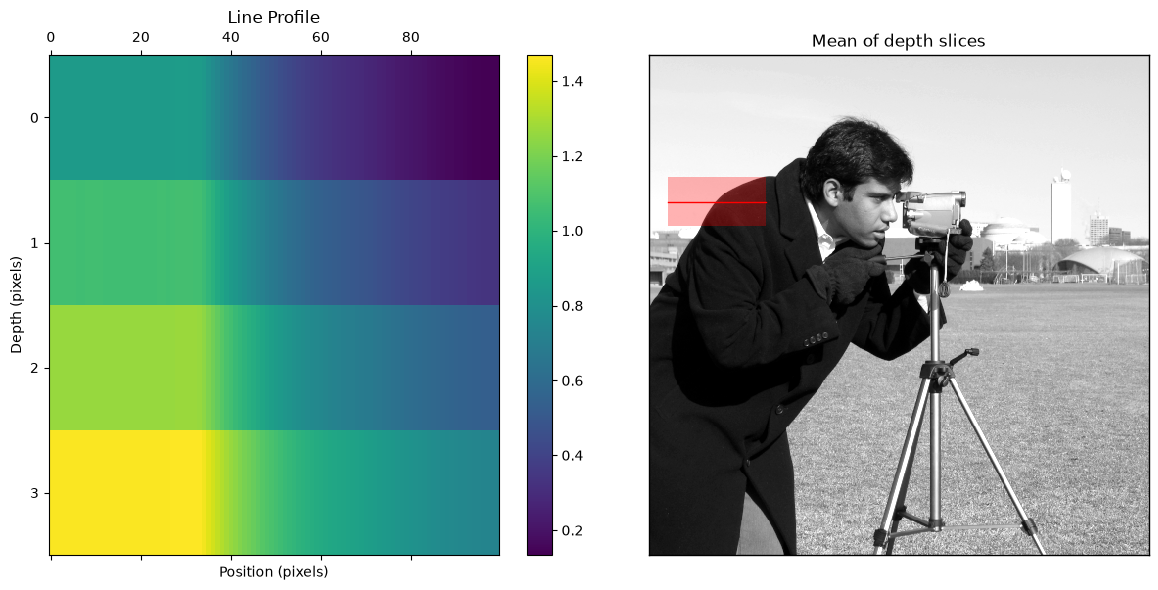

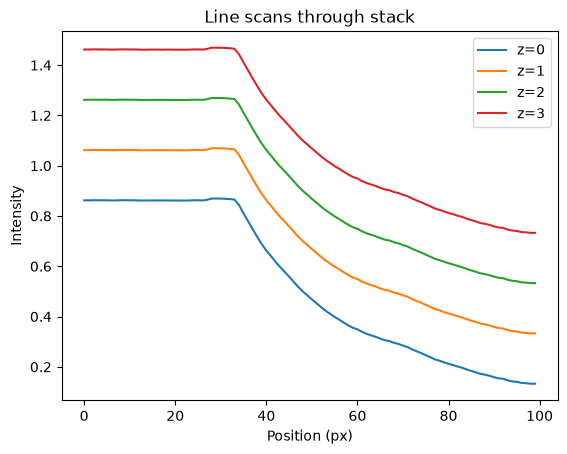

In [41]:
# 3D line scan
cameraman_3d = np.stack([cameraman, cameraman+0.2, cameraman+0.4, cameraman+0.6])
pos3d, prof3d = linescan(cameraman_3d, show=True, center=(150, 70), line_len=100, linewidth=50)

fig, ax = plt.subplots()
ax.plot(pos3d, prof3d.T, label=["z=0", "z=1", "z=2", "z=3"])
ax.set_xlabel("Position (px)")
ax.set_ylabel("Intensity")
ax.set_title("Line scans through stack")
ax.legend()
plt.show()


*End of notebook.*
